## Residual Conformal Monitor
Can a model of nominal spacecraft telemetry behaviour produce useful residual-based anomaly scores, with thresholds calibrated using split conformal prediction?

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.compose import TransformedTargetRegressor

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    balanced_accuracy_score,
    average_precision_score
)

#### Load and filter the data

In [2]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

df = pd.read_csv(
    PROJECT_ROOT / "data" / "raw" / "segments.csv"
)

df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    utc=True
)

df["value"] = pd.to_numeric(
    df["value"],
    errors="raise"
)

CHANNEL = "CADC0872"
SAMPLING = 5

channel_df = df[
    (df["channel"] == CHANNEL)
    &
    (df["sampling"] == SAMPLING)
].copy()

channel_df = channel_df.sort_values(
    ["segment", "timestamp"]
)

print("Selected measurements:", len(channel_df))
print("Unique segments:", channel_df["segment"].nunique())
print(channel_df.head())

Selected measurements: 14709
Unique segments: 328
         channel                 timestamp     value    label  sampling  \
288784  CADC0872 2022-02-05 12:35:02+00:00 -0.000015  anomaly         5   
288785  CADC0872 2022-02-05 12:35:07+00:00 -0.000013  anomaly         5   
288786  CADC0872 2022-02-05 12:35:12+00:00 -0.000013  anomaly         5   
288787  CADC0872 2022-02-05 12:35:17+00:00 -0.000014  anomaly         5   
288788  CADC0872 2022-02-05 12:35:22+00:00 -0.000014  anomaly         5   

        anomaly  segment  train  
288784        0     1796      1  
288785        0     1796      1  
288786        0     1796      1  
288787        0     1796      1  
288788        0     1796      1  


In [3]:
segment_metadata = (

    channel_df

    .groupby("segment")

    .agg(

        anomaly=("anomaly", "first"),

        train=("train", "first"),

        n_samples=("value", "size"),

        sampling=("sampling", "first"),

        timestamp_start=("timestamp", "min"),

        timestamp_end=("timestamp", "max")

    )

    .reset_index()

)

print("Total selected segments:", len(segment_metadata))

display(
    segment_metadata["anomaly"]
    .value_counts()
)

Total selected segments: 328


anomaly
0    275
1     53
Name: count, dtype: int64

In [4]:
assert len(segment_metadata) == 328

assert (
    len(segment_metadata[
        (segment_metadata["train"] == 1)
        &
        (segment_metadata["anomaly"] == 0)
    ]) == 209
)

assert (
    len(segment_metadata[
        (segment_metadata["train"] == 1)
        &
        (segment_metadata["anomaly"] == 1)
    ]) == 38
)

assert (
    len(segment_metadata[
        (segment_metadata["train"] == 0)
        &
        (segment_metadata["anomaly"] == 0)
    ]) == 66
)

assert (
    len(segment_metadata[
        (segment_metadata["train"] == 0)
        &
        (segment_metadata["anomaly"] == 1)
    ]) == 15
)

print("Experimental subset validated.")

Experimental subset validated.


#### Separate model fitting, calibration and test data

In [5]:
nominal_train = segment_metadata[
    (segment_metadata["train"] == 1)
    &
    (segment_metadata["anomaly"] == 0)
].copy()

anomalous_train = segment_metadata[
    (segment_metadata["train"] == 1)
    &
    (segment_metadata["anomaly"] == 1)
].copy()

test_segments = segment_metadata[
    segment_metadata["train"] == 0
].copy()

fit_segments, calibration_segments = train_test_split(
    nominal_train,
    test_size=0.20,
    random_state=42
)

print("Model-fitting segments:", len(fit_segments))
print("Calibration segments:", len(calibration_segments))
print("Anomalous training segments:", len(anomalous_train))
print("Test segments:", len(test_segments))

Model-fitting segments: 167
Calibration segments: 42
Anomalous training segments: 38
Test segments: 81


#### Prepare individual telemetry sequences

In [6]:
segment_signals = {}

for segment_id, group in channel_df.groupby("segment"):

    ordered = group.sort_values("timestamp")

    values = ordered["value"].to_numpy(dtype=float)

    if not np.isfinite(values).all():
        raise ValueError(
            f"Non-finite values in segment {segment_id}"
        )

    if len(values) < 10:
        raise ValueError(
            f"Segment {segment_id} is too short."
        )

    segment_signals[int(segment_id)] = values

print("Stored telemetry sequences:", len(segment_signals))

Stored telemetry sequences: 328


#### Create lagged observations

In [7]:
def create_lagged_windows(
    values: np.ndarray,
    n_lags: int = 5
):
    """
    Construct autoregressive input-output pairs
    from a single telemetry segment.

    No windows cross segment boundaries.
    """

    values = np.asarray(values, dtype=float)

    if values.ndim != 1:
        raise ValueError("Telemetry must be one-dimensional.")

    if len(values) <= n_lags:
        raise ValueError("Segment is too short.")

    if not np.isfinite(values).all():
        raise ValueError("Telemetry contains non-finite values.")

    windows = np.lib.stride_tricks.sliding_window_view(
        values,
        window_shape=n_lags + 1
    )

    X = windows[:, :-1].copy()

    y = windows[:, -1].copy()

    return X, y

In [8]:
example = np.array([1, 2, 3, 4, 5, 6, 7])

X_example, y_example = create_lagged_windows(
    example,
    n_lags=3
)

display(pd.DataFrame(
    np.column_stack([X_example, y_example]),
    columns=["lag_3", "lag_2", "lag_1", "target"]
))

,lag_3,lag_2,lag_1,target
0,1.0,2.0,3.0,4.0
1,2.0,3.0,4.0,5.0
2,3.0,4.0,5.0,6.0
3,4.0,5.0,6.0,7.0


#### Construct the model-fitting matrix

In [9]:
N_LAGS = 5

X_parts = []
y_parts = []

for segment_id in fit_segments["segment"]:

    values = segment_signals[int(segment_id)]

    X_segment, y_segment = create_lagged_windows(
        values,
        n_lags=N_LAGS
    )

    X_parts.append(X_segment)
    y_parts.append(y_segment)

X_fit = np.vstack(X_parts)
y_fit = np.concatenate(y_parts)

print("Training input shape:", X_fit.shape)
print("Training target shape:", y_fit.shape)

print("All finite:", np.isfinite(X_fit).all())

Training input shape: (5973, 5)
Training target shape: (5973,)
All finite: True


#### Fit Ridge

In [10]:
model = TransformedTargetRegressor(

    regressor=make_pipeline(

        StandardScaler(),

        Ridge(alpha=1.0)

    ),

    transformer=StandardScaler()

)

model.fit(
    X_fit,
    y_fit
)

print("Ridge autoregressive model fitted.")

print("Number of training windows:", len(y_fit))

Ridge autoregressive model fitted.
Number of training windows: 5973


#### Implement residual scoring

In [11]:
def calculate_segment_score(
    segment_id: int,
    model,
    n_lags: int = 5,
    residual_quantile: float = 0.95
):
    """
    Calculate a segment-level anomaly score
    using the 95th percentile of absolute
    one-step-ahead prediction residuals.
    """

    values = segment_signals[int(segment_id)]

    X_segment, y_segment = create_lagged_windows(
        values,
        n_lags=n_lags
    )

    predictions = model.predict(X_segment)

    residuals = np.abs(
        y_segment - predictions
    )

    score = np.quantile(
        residuals,
        residual_quantile
    )

    return {
        "segment": int(segment_id),

        "score": float(score),

        "mean_residual": float(residuals.mean()),

        "max_residual": float(residuals.max()),

        "n_predictions": len(residuals)

    }

#### Calculate calibration scores

In [12]:
calibration_records = []

for segment_id in calibration_segments["segment"]:

    result = calculate_segment_score(
        segment_id,
        model,
        n_lags=N_LAGS
    )

    calibration_records.append(result)

calibration_scores = pd.DataFrame(
    calibration_records
)

print("Calibration segments:", len(calibration_scores))

display(
    calibration_scores["score"].describe()
)

Calibration segments: 42


count    42.000000
mean      0.000003
std       0.000002
min       0.000001
25%       0.000002
50%       0.000002
75%       0.000004
max       0.000007
Name: score, dtype: float64

#### Conformal threshold calibration

In [13]:
import math


def conformal_upper_threshold(
    scores: np.ndarray,
    alpha: float
) -> float:

    scores = np.asarray(scores, dtype=float)

    if scores.ndim != 1 or len(scores) == 0:
        raise ValueError("Scores must be a non-empty vector.")

    if not np.isfinite(scores).all():
        raise ValueError("Scores must be finite.")

    if not 0 < alpha < 1:
        raise ValueError("Alpha must be between 0 and 1.")

    n = len(scores)

    k = math.ceil(
        (n + 1) * (1 - alpha)
    )

    if k > n:
        return float("inf")

    return float(
        np.sort(scores)[k - 1]
    )

In [14]:
thresholds = {}

for alpha in [0.10, 0.05]:

    threshold = conformal_upper_threshold(
        calibration_scores["score"].to_numpy(),
        alpha=alpha
    )

    thresholds[alpha] = threshold

    print(f"\nNominal coverage target: {1-alpha:.0%}")

    print(f"Anomaly significance level: {alpha:.0%}")

    print(f"Threshold: {threshold:.8f}")


Nominal coverage target: 90%
Anomaly significance level: 10%
Threshold: 0.00000557

Nominal coverage target: 95%
Anomaly significance level: 5%
Threshold: 0.00000702


#### Calculate test scores

In [15]:
test_records = []

for row in test_segments.itertuples(index=False):

    result = calculate_segment_score(
        row.segment,
        model,
        n_lags=N_LAGS
    )

    result["anomaly"] = int(row.anomaly)

    result["sampling"] = int(row.sampling)

    test_records.append(result)

test_results = pd.DataFrame(test_records)

print("Evaluated test segments:", len(test_results))

display(test_results.head())

Evaluated test segments: 81


,segment,score,mean_residual,max_residual,n_predictions,anomaly,sampling
0,1803,0.000010,1.772730e-06,0.000035,182,1,5
1,1805,0.000004,2.405082e-06,0.000084,119,1,5
2,1812,0.000088,1.655086e-05,0.000137,132,1,5
3,1816,0.000002,7.340614e-07,0.000002,132,0,5
4,1820,0.000007,2.760886e-06,0.000009,11,0,5


#### Evaluate false alarms and anomaly detection

In [16]:
evaluation_records = []

y_true = test_results["anomaly"].to_numpy()

scores = test_results["score"].to_numpy()

for alpha, threshold in thresholds.items():

    y_pred = (
        scores > threshold
    ).astype(int)

    nominal_mask = y_true == 0

    anomalous_mask = y_true == 1

    false_alarm_rate = (
        y_pred[nominal_mask].mean()
    )

    anomaly_recall = (
        y_pred[anomalous_mask].mean()
    )

    evaluation_records.append({

        "target_nominal_coverage": 1 - alpha,

        "threshold": threshold,

        "false_alarm_rate": false_alarm_rate,

        "anomaly_recall": anomaly_recall,

        "precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "f1": f1_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "average_precision": average_precision_score(
            y_true,
            scores
        )

    })

evaluation_results = pd.DataFrame(
    evaluation_records
)

display(
    evaluation_results.round(4)
)

,target_nominal_coverage,threshold,false_alarm_rate,anomaly_recall,precision,f1,balanced_accuracy,average_precision
0,0.90,0.0,0.1061,0.8,0.6316,0.7059,0.8470,0.8624
1,0.95,0.0,0.0303,0.8,0.8571,0.8276,0.8848,0.8624


#### Create a confusion matrix

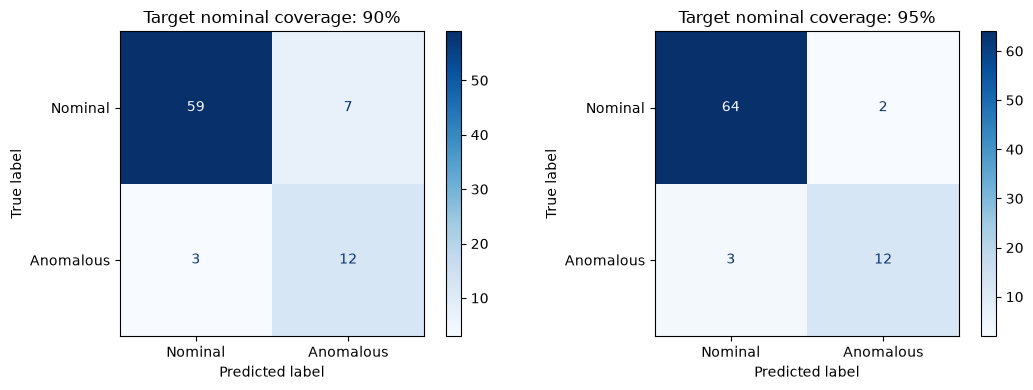

In [17]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(
    1,
    2,
    figsize=(11, 4)
)

for ax, alpha in zip(axes, [0.10, 0.05]):

    threshold = thresholds[alpha]

    y_pred = (
        scores > threshold
    ).astype(int)

    ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        labels=[0, 1],
        display_labels=["Nominal", "Anomalous"],
        cmap="Blues",
        values_format="d",
        ax=ax
    )

    ax.set_title(
        f"Target nominal coverage: {1-alpha:.0%}"
    )

plt.tight_layout()

figures_dir = (
    PROJECT_ROOT
    / "reports"
    / "figures"
)

figures_dir.mkdir(
    parents=True,
    exist_ok=True
)

fig.savefig(
    figures_dir / "conformal_anomaly_confusion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Visualise nominal and anomalous residual scores

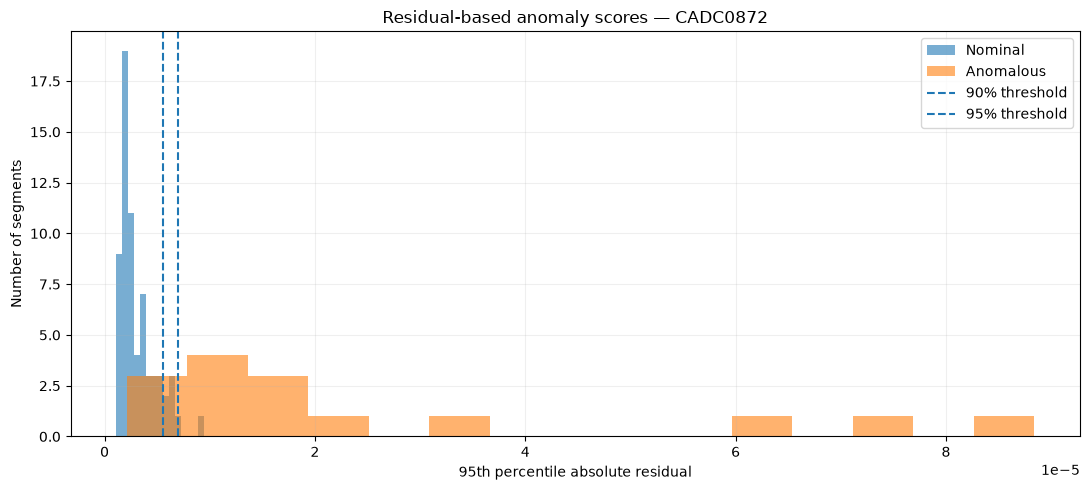

In [18]:
fig, ax = plt.subplots(figsize=(11, 5))

nominal_scores = test_results.loc[
    test_results["anomaly"] == 0,
    "score"
]

anomalous_scores = test_results.loc[
    test_results["anomaly"] == 1,
    "score"
]

ax.hist(
    nominal_scores,
    bins=15,
    alpha=0.6,
    label="Nominal"
)

ax.hist(
    anomalous_scores,
    bins=15,
    alpha=0.6,
    label="Anomalous"
)

for alpha, threshold in thresholds.items():

    ax.axvline(
        threshold,
        linestyle="--",
        linewidth=1.5,
        label=f"{1-alpha:.0%} threshold"
    )

ax.set_title(
    "Residual-based anomaly scores — CADC0872"
)

ax.set_xlabel("95th percentile absolute residual")

ax.set_ylabel("Number of segments")

ax.legend()

ax.grid(alpha=0.2)

plt.tight_layout()

fig.savefig(
    figures_dir / "residual_score_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Compare against a simple persistence baseline

In [19]:
def calculate_persistence_score(
    segment_id: int,
    residual_quantile: float = 0.95
):
    """
    One-step persistence prediction:
        x_hat[t] = x[t-1]

    Produces a segment-level anomaly score
    using the 95th percentile of absolute residuals.
    """

    values = segment_signals[int(segment_id)]

    predictions = values[:-1]

    actual = values[1:]

    residuals = np.abs(
        actual - predictions
    )

    return {
        "segment": int(segment_id),

        "score": float(
            np.quantile(
                residuals,
                residual_quantile
            )
        ),

        "mean_residual": float(
            residuals.mean()
        ),

        "max_residual": float(
            residuals.max()
        )
    }

In [20]:
persistence_calibration = pd.DataFrame([

    calculate_persistence_score(segment_id)

    for segment_id in calibration_segments["segment"]

])

print("Calibration segments:", len(persistence_calibration))

display(
    persistence_calibration["score"].describe()
)

Calibration segments: 42


count    42.000000
mean      0.000008
std       0.000004
min       0.000002
25%       0.000004
50%       0.000007
75%       0.000012
max       0.000015
Name: score, dtype: float64

In [21]:
persistence_test = pd.DataFrame([

    calculate_persistence_score(segment_id)

    for segment_id in test_segments["segment"]

])

persistence_test = persistence_test.merge(
    test_segments[["segment", "anomaly"]],
    on="segment",
    validate="one_to_one"
)

print("Test segments:", len(persistence_test))

Test segments: 81


In [22]:
from sklearn.metrics import (
    confusion_matrix,
    f1_score,
    balanced_accuracy_score,
    precision_score,
    average_precision_score
)

detectors = {

    "Ridge AR(5)": (
        calibration_scores,
        test_results
    ),

    "Persistence": (
        persistence_calibration,
        persistence_test
    )

}

baseline_comparison = []

for detector_name, (cal_data, test_data) in detectors.items():

    y_true = test_data["anomaly"].to_numpy()

    test_scores = test_data["score"].to_numpy()

    for alpha in [0.10, 0.05]:

        threshold = conformal_upper_threshold(
            cal_data["score"].to_numpy(),
            alpha=alpha
        )

        y_pred = (
            test_scores > threshold
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true,
            y_pred,
            labels=[0, 1]
        ).ravel()

        baseline_comparison.append({

            "model": detector_name,

            "target_coverage": 1-alpha,

            "threshold": threshold,

            "false_alarms": fp,

            "detected_anomalies": tp,

            "false_alarm_rate": fp/(tn+fp),

            "anomaly_recall": tp/(tp+fn),

            "precision": precision_score(
                y_true,
                y_pred,
                zero_division=0
            ),

            "f1": f1_score(
                y_true,
                y_pred,
                zero_division=0
            ),

            "balanced_accuracy": balanced_accuracy_score(
                y_true,
                y_pred
            ),

            "average_precision": average_precision_score(
                y_true,
                test_scores
            )

        })

baseline_comparison_df = pd.DataFrame(
    baseline_comparison
)

display(
    baseline_comparison_df.round(4)
)

,model,target_coverage,threshold,false_alarms,detected_anomalies,false_alarm_rate,anomaly_recall,precision,f1,balanced_accuracy,average_precision
0,Ridge AR(5),0.90,0.0,7,12,0.1061,0.8000,0.6316,0.7059,0.8470,0.8624
1,Ridge AR(5),0.95,0.0,2,12,0.0303,0.8000,0.8571,0.8276,0.8848,0.8624
2,Persistence,0.90,0.0,5,5,0.0758,0.3333,0.5000,0.4000,0.6288,0.4428
3,Persistence,0.95,0.0,1,5,0.0152,0.3333,0.8333,0.4762,0.6591,0.4428


### Investigate the three missed anomalies

In [23]:
threshold_95 = thresholds[0.05]

test_results["predicted_anomaly_95"] = (
    test_results["score"] > threshold_95
).astype(int)

false_negatives = test_results[
    (test_results["anomaly"] == 1)
    &
    (test_results["predicted_anomaly_95"] == 0)
].copy()

false_positives = test_results[
    (test_results["anomaly"] == 0)
    &
    (test_results["predicted_anomaly_95"] == 1)
].copy()

print("Missed anomalies:", len(false_negatives))

display(
    false_negatives.sort_values("score")
)

print("False alarms:", len(false_positives))

display(
    false_positives.sort_values("score", ascending=False)
)

Missed anomalies: 3


,segment,score,mean_residual,max_residual,n_predictions,anomaly,sampling,predicted_anomaly_95
38,1955,0.000002,0.000001,0.000015,114,1,5,0
39,1956,0.000003,0.000001,0.000018,127,1,5,0
1,1805,0.000004,0.000002,0.000084,119,1,5,0


False alarms: 2


,segment,score,mean_residual,max_residual,n_predictions,anomaly,sampling,predicted_anomaly_95
21,1892,0.000009,0.000003,0.000011,15,0,5,1
4,1820,0.000007,0.000003,0.000009,11,0,5,1


### Check segment length

In [24]:
length_check = (

    calibration_scores

    .merge(
        calibration_segments[
            ["segment", "n_samples"]
        ],
        on="segment"
    )

)

length_check["n_predictions"] = (
    length_check["n_samples"] - N_LAGS
)

display(
    length_check[
        ["n_samples", "n_predictions", "score"]
    ].describe().round(3)
)

,n_samples,n_predictions,score
count,42.000,42.000,42.0
mean,37.452,32.452,0.0
std,27.623,27.623,0.0
min,16.000,11.000,0.0
25%,19.000,14.000,0.0
50%,21.000,16.000,0.0
75%,48.000,43.000,0.0
max,133.000,128.000,0.0


In [25]:
from scipy.stats import spearmanr

correlation, p_value = spearmanr(
    length_check["n_predictions"],
    length_check["score"]
)

print("Spearman correlation:", correlation)

print("P-value:", p_value)

Spearman correlation: -0.6865748263609465
P-value: 5.168432610061786e-07


In [26]:
# Compare nominal segment lengths
# in calibration and official test data.

calibration_lengths = (
    calibration_scores
    .merge(
        calibration_segments[["segment", "n_samples"]],
        on="segment"
    )
)

test_nominal_lengths = test_results[
    test_results["anomaly"] == 0
]["n_predictions"]

print("Calibration segment lengths:")
display(
    calibration_lengths["n_predictions"].describe()
)

print("\nTest nominal segment lengths:")
display(
    test_nominal_lengths.describe()
)

Calibration segment lengths:


count     42.000000
mean      32.452381
std       27.623075
min       11.000000
25%       14.000000
50%       16.000000
75%       43.000000
max      128.000000
Name: n_predictions, dtype: float64


Test nominal segment lengths:


count     66.000000
mean      28.287879
std       26.376426
min        9.000000
25%       12.000000
50%       15.000000
75%       43.750000
max      132.000000
Name: n_predictions, dtype: float64

In [27]:
from scipy.stats import spearmanr

test_nominal_scores = test_results[
    test_results["anomaly"] == 0
]

rho, p_value = spearmanr(
    test_nominal_scores["n_predictions"],
    test_nominal_scores["score"]
)

print("Test nominal Spearman correlation:", rho)
print("P-value:", p_value)

Test nominal Spearman correlation: -0.5693795836484111
P-value: 6.071219882747575e-07
